<a href="https://colab.research.google.com/github/RoihansLab/Machine-Learning-Projects/blob/main/Praktikum_Matkul/PraktikumM3_MultiClass_Regression_Latihan.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [1]:
from sklearn.model_selection import train_test_split
from sklearn import datasets, linear_model, metrics
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import make_pipeline
import matplotlib.pyplot as plt
import numpy as np
from sklearn.metrics import ConfusionMatrixDisplay

In [2]:
digits = datasets.load_digits()
X = digits.data
y = digits.target

print("Jumlah seluruh gambar:", X.shape[0])
print("jumlah fitur per gambar:", X.shape[1])
print("Kelas angka", np.unique(y))


Jumlah seluruh gambar: 1797
jumlah fitur per gambar: 64
Kelas angka [0 1 2 3 4 5 6 7 8 9]


In [3]:
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.4,
    random_state = 1,
    stratify=y
)

print("\njumlah data training:", X_train.shape[0])
print("jumlah data testing:", X_test.shape[0])


jumlah data training: 1078
jumlah data testing: 719


In [4]:
reg = make_pipeline(
    StandardScaler(),
    linear_model.LogisticRegression(
        max_iter=10000,
        random_state=0
    )
)

In [5]:
reg.fit(X_train, y_train)
print("\n model selesai di latih")


 model selesai di latih


In [6]:
y_pred = reg.predict(X_test)
y_prob = reg.predict_proba(X_test)

print("n\Contoh lima sample pertama:")
print("Label aktual:", y_test[:5])
print("label prediksi:", y_pred[:5])

print("\nProbabilitas sample pertama:")
print(np.round(y_prob[0], 3))

n\Contoh lima sample pertama:
Label aktual: [9 9 5 4 9]
label prediksi: [9 5 5 4 9]

Probabilitas sample pertama:
[0.    0.    0.    0.004 0.    0.011 0.    0.    0.014 0.97 ]


<>:4: SyntaxWarning: invalid escape sequence '\C'
<>:4: SyntaxWarning: invalid escape sequence '\C'
/tmp/ipykernel_6710/2995799305.py:4: SyntaxWarning: invalid escape sequence '\C'
  print("n\Contoh lima sample pertama:")


In [7]:
accuracy = metrics.accuracy_score(y_test, y_pred)

precision = metrics.precision_score(
    y_test, y_pred, average="macro", zero_division=0
)

recall = metrics.recall_score(
    y_test, y_pred, average="macro", zero_division=0
)

recall = metrics.recall_score(
    y_test, y_pred, average="macro", zero_division=0
)

f1 = metrics.f1_score(
    y_test, y_pred, average="macro", zero_division=0
)

roc_auc = metrics.roc_auc_score(
    y_test,
    y_prob,
    multi_class="ovr",
    average="macro",
    labels=reg.classes_ if hasattr(reg, "classes_") else
        reg.named_steps["logisticregression"].classes_
)

print("\n================= Hasil Evaluasi =============")
print(f" Accuracy : {accuracy * 100:.2f}%")
print(f"Precision macro: {precision:.4f}")
print(f"Recall macro: {recall:.4f}")
print(f"F1 score macro: {f1:.4f}")
print(f"ROC AUC score: {roc_auc:.4f}")


================= Hasil Evaluasi =============
 Accuracy : 96.52%
Precision macro: 0.9655
Recall macro: 0.9652
F1 score macro: 0.9652
ROC AUC score: 0.9989


In [8]:
print("\n==============Classificatio Report =================")
print(metrics.classification_report(y_test, y_pred, labels=np.arange(10), zero_division=0)
)


==============Classificatio Report =================
              precision    recall  f1-score   support

           0       0.99      1.00      0.99        71
           1       0.92      0.97      0.95        73
           2       0.97      0.97      0.97        71
           3       0.99      0.97      0.98        73
           4       0.97      0.97      0.97        72
           5       0.96      0.93      0.94        73
           6       0.99      0.97      0.98        72
           7       0.99      0.99      0.99        72
           8       0.94      0.91      0.93        70
           9       0.95      0.96      0.95        72

    accuracy                           0.97       719
   macro avg       0.97      0.97      0.97       719
weighted avg       0.97      0.97      0.97       719




================= Confusion Matrix =============
[[71  0  0  0  0  0  0  0  0  0]
 [ 0 71  0  0  0  0  0  0  2  0]
 [ 0  2 69  0  0  0  0  0  0  0]
 [ 0  0  0 71  0  1  0  0  1  0]
 [ 0  0  0  0 70  0  0  1  0  1]
 [ 0  0  1  0  1 68  1  0  0  2]
 [ 0  0  0  0  0  1 70  0  1  0]
 [ 0  0  0  0  0  0  0 71  0  1]
 [ 1  3  1  0  1  0  0  0 64  0]
 [ 0  1  0  1  0  1  0  0  0 69]]


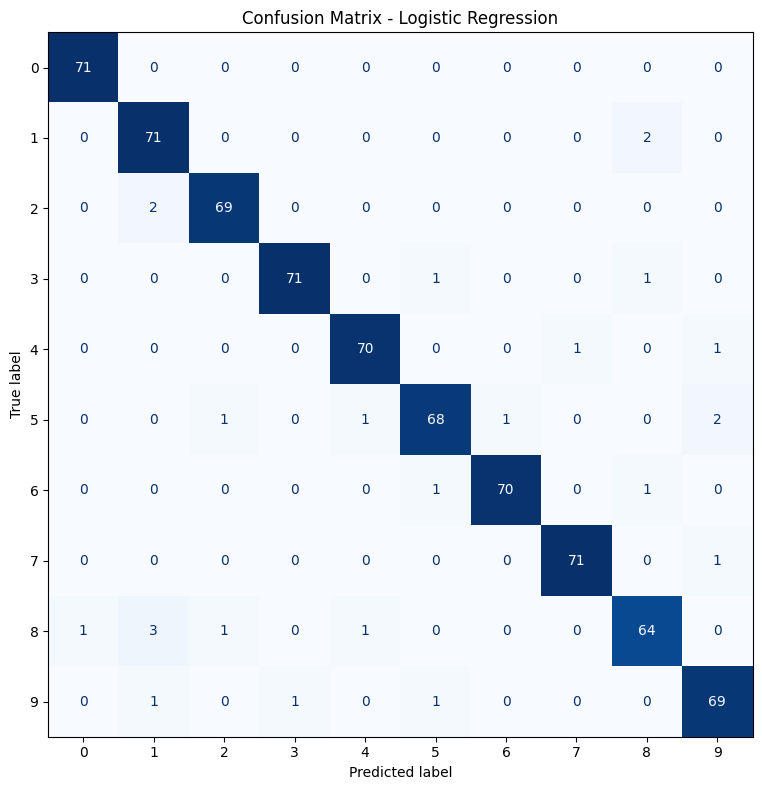

In [9]:
cm = metrics.confusion_matrix(
    y_test,
    y_pred,
    labels=np.arange(10)
)

print("\n================= Confusion Matrix =============")
print(cm)

disp = ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=np.arange(10)
)

fig, ax = plt.subplots(figsize=(9, 8))
disp.plot(
    ax=ax,
    cmap="Blues",
    values_format="d",
    colorbar=False
)

plt.title("Confusion Matrix - Logistic Regression")
plt.tight_layout()
plt.show()

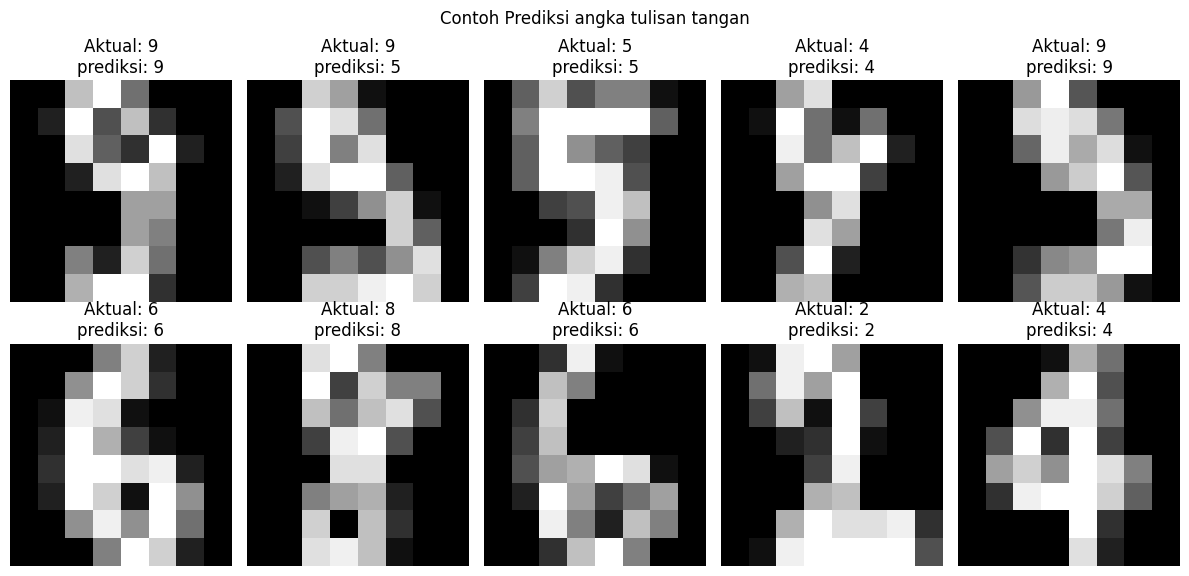

In [12]:
fig, axes = plt.subplots(2, 5, figsize=(12, 6))

for i, ax in enumerate(axes.flat):
  original_index = np.where(
      (digits.data == X_test[i]).all(axis=1)
  )[0][0]

  image = digits.images[original_index]

  ax.imshow(image, cmap="gray")
  ax.set_title(
      f"Aktual: {y_test[i]}\nprediksi: {y_pred[i]}")
  ax.axis("off")

plt.suptitle("Contoh Prediksi angka tulisan tangan")
plt.tight_layout()
plt.show()